# RentWise IDSS: exploratory data analysis and preprocessing
Dataset: UCI *Apartment for Rent Classified* (id 555), 100K file. Raw files in `data/raw/` stay unchanged; the cleaning logic lives in `src/preprocessing.py` and is only *called* here.

In [ ]:
import sys; sys.path.insert(0, '..')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.preprocessing import RAW, clean, load_raw

pd.set_option('display.max_columns', 50)
raw = load_raw(RAW)
raw.shape

(99492, 22)

## 1. Structure and types

In [2]:
raw.head(3)

,id,category,title,body,amenities,bathrooms,bedrooms,currency,fee,has_photo,pets_allowed,price,price_display,price_type,square_feet,address,cityname,state,latitude,longitude,source,time
0,5668640009,housing/rent/apartment,One BR 507 & 509 Esplanade,"This unit is located at 507 & 509 Esplanade, R...",NaN,1.0,1.0,USD,No,Thumbnail,Cats,2195.0,"$2,195",Monthly,542,507 509 Esplanade,Redondo Beach,CA,33.8520,-118.3759,RentLingo,1577360355
1,5668639818,housing/rent/apartment,Three BR 146 Lochview Drive,"This unit is located at 146 Lochview Drive, Ne...",NaN,1.5,3.0,USD,No,Thumbnail,"Cats,Dogs",1250.0,"$1,250",Monthly,1500,146 Lochview Dr,Newport News,VA,37.0867,-76.4941,RentLingo,1577360340
2,5668639686,housing/rent/apartment,Three BR 3101 Morningside Drive,This unit is located at 3101 Morningside Drive...,NaN,2.0,3.0,USD,No,Thumbnail,NaN,1395.0,"$1,395",Monthly,1650,3101 Morningside Dr,Raleigh,NC,35.8230,-78.6438,RentLingo,1577360332


In [3]:
raw.dtypes.to_frame('dtype').T

,id,category,title,body,amenities,bathrooms,bedrooms,currency,fee,has_photo,pets_allowed,price,price_display,price_type,square_feet,address,cityname,state,latitude,longitude,source,time
dtype,int64,str,str,str,str,float64,float64,str,str,str,str,float64,str,str,int64,str,str,str,float64,float64,str,int64


## 2. Missing values

In [4]:
na = raw.isna().sum(); (na[na > 0] / len(raw) * 100).round(2).sort_values(ascending=False).to_frame('% missing')

,% missing
address,92.02
pets_allowed,60.73
amenities,16.13
cityname,0.30
state,0.30
bedrooms,0.12
bathrooms,0.06
latitude,0.03
longitude,0.03
price,0.00


`address` (92%) and `pets_allowed` (61%) are mostly empty, `amenities` 16%. For pets and amenities missing means *not stated*, not *absent*, so we keep an explicit `*_unknown` flag instead of imputing.

## 3. Categorical columns

In [5]:
for c in ['category','price_type','currency','fee','has_photo','pets_allowed','source']:
    print(raw[c].value_counts(dropna=False).head(8), '\n')

category
housing/rent/apartment            99431
housing/rent/commercial/retail       42
housing/rent                          7
housing/rent/home                     4
housing/rent/short_term               4
housing/rent/condo                    3
housing/rent/other                    1
Name: count, dtype: int64 

price_type
Monthly           99488
Weekly                3
Monthly|Weekly        1
Name: count, dtype: int64 

currency
USD    99492
Name: count, dtype: int64 

fee
No     99291
Yes      201
Name: count, dtype: int64 

has_photo
Yes          55974
Thumbnail    34303
No            9215
Name: count, dtype: int64 

pets_allowed
NaN               60424
Cats,Dogs         37097
Cats               1843
Dogs                127
Cats,Dogs,None        1
Name: count, dtype: int64 

source
RentDigs.com        90912
RentLingo            6924
ListedBuy             571
GoSection8            437
RealRentals           268
tenantcloud           124
BostonApartments       94
RENTCafé           

Almost everything is `housing/rent/apartment`, monthly, USD. `currency` and `fee` carry (almost) no information.

## 4. Duplicates

In [6]:
k = ['latitude','longitude','price','square_feet','bedrooms','bathrooms']
d = raw.drop_duplicates()
print('exact duplicate rows:', raw.duplicated().sum())
print('same description + attributes (reposts):', d.duplicated(subset=k+['body']).sum())
print('same attributes only (often different units in one complex):', d.duplicated(subset=k).sum())

exact duplicate rows: 84
same description + attributes (reposts): 755
same attributes only (often different units in one complex): 14608


In [7]:
rep = d[d.duplicated(subset=k+['body'], keep=False)].sort_values(k)
rep[['id','title','price','cityname','time','source']].head(6)

,id,title,price,cityname,time,source
83806,5121844033,Apartment in move in condition in Hollywood,1631.0,Hollywood,1544233364,RentDigs.com
94342,5121843769,Convenient location Two BR Two BA for rent,1631.0,Hollywood,1544233337,RentDigs.com
20263,5508657728,Bradenton Luxurious 1 + 1,915.0,Bradenton,1568744154,RentDigs.com
24425,5508660537,Apartment only for $915/mo. You Can Stop Looki...,915.0,Bradenton,1568744351,RentDigs.com
85265,5122373077,"Corpus Christi, Great Location, One BR Apartme...",723.0,Corpus Christi,1544278441,RentDigs.com
89685,5122370572,Apartment only for $723/mo. You Can Stop Looki...,723.0,Corpus Christi,1544278340,RentDigs.com


Reposts are the same unit posted twice within seconds under different click-bait titles → drop, keep the latest. Listings that only share the attributes are kept: those are typically several identical units in the same building.

## 5. Numeric distributions and outliers

In [8]:
num = raw[['price','square_feet','bedrooms','bathrooms']].copy(); num['price_per_sqft'] = raw.price / raw.square_feet
num.describe(percentiles=[.001,.01,.5,.99,.999]).round(2)

,price,square_feet,bedrooms,bathrooms,price_per_sqft
count,99491.00,99492.00,99368.00,99429.00,99491.00
mean,1527.06,956.43,1.73,1.45,1.69
std,904.25,417.57,0.75,0.55,0.86
min,100.00,101.00,0.00,1.00,0.05
0.1%,400.00,250.00,0.00,1.00,0.40
1%,545.00,396.91,1.00,1.00,0.62
50%,1350.00,900.00,2.00,1.00,1.47
99%,4250.00,2260.00,4.00,3.00,4.68
99.9%,9000.00,3894.11,5.00,4.00,7.24
max,52500.00,50000.00,9.00,9.00,37.02


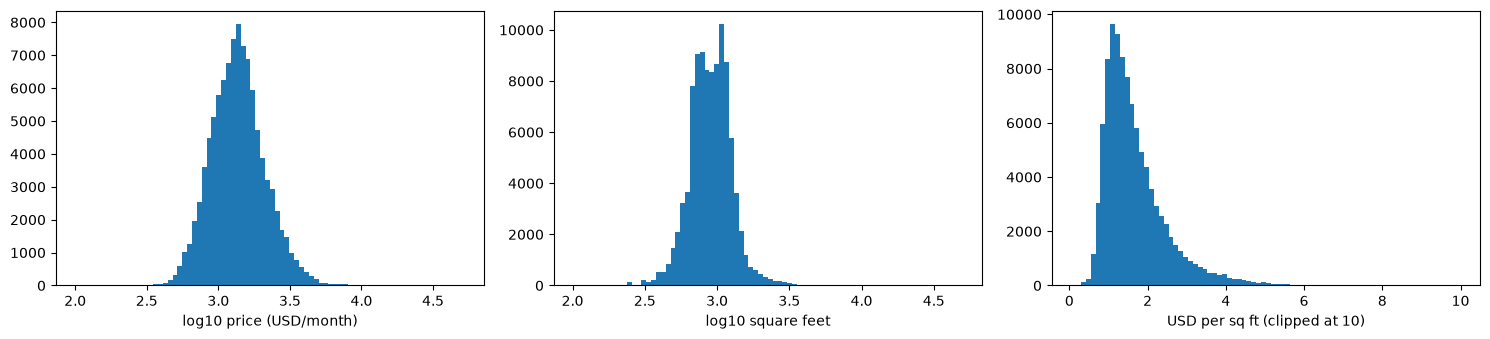

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].hist(np.log10(raw.price.dropna()), bins=80); ax[0].set_xlabel('log10 price (USD/month)')
ax[1].hist(np.log10(raw.square_feet), bins=80); ax[1].set_xlabel('log10 square feet')
ax[2].hist(num.price_per_sqft.clip(upper=10), bins=80); ax[2].set_xlabel('USD per sq ft (clipped at 10)')
plt.tight_layout()

In [10]:
raw.loc[raw.price > 15000, ['price','square_feet','bedrooms','cityname','title']].head(8)

,price,square_feet,bedrooms,cityname,title
3487,25000.0,8716,6.0,Montecito,Six BR 256 Las Entradas
6574,19500.0,5000,4.0,Los Angeles,Four BR 864 Teakwood Rd
6863,52500.0,1418,0.0,Barstow,Studio apartment for rent
14400,30000.0,5872,5.0,Snowmass Village,This mountain contemporary is truly one of a k...
17131,35000.0,2269,4.0,West Hollywood,Four BR - ready to move in.
18325,20000.0,2866,3.0,West Hollywood,"West Hollywood - 3bd/3.25 BA 2,866sqft Apartme..."
23574,25000.0,6881,4.0,Playa Del Rey,Four BR Apartment - Beautiful bluff top proper...
23888,23000.0,3280,3.0,Los Angeles,Three BR Apartment - At The Century you will e...


In [11]:
raw.loc[raw.price < 300, ['price','square_feet','bedrooms','price_type','title']]

,price,square_feet,bedrooms,price_type,title
3769,288.0,766,1.0,Monthly,One BR 1200 Mallard Drive
4417,224.0,587,1.0,Monthly,Studio apartment 116 N 2nd St
6286,200.0,250,1.0,Monthly,One BR Ridge Road
7245,275.0,300,NaN,Monthly|Weekly,A-P-T Suites Lakeland - Low Weekly & Monthly R...
22869,264.0,750,1.0,Monthly,Come home to Auburn Trace Apartments. $264/mo
51823,100.0,800,2.0,Monthly,Park Management LLC
52588,299.0,736,1.0,Monthly,Columbus - 1bd/One BA 736sqft Apartment for re...
53007,200.0,800,0.0,Monthly,"Studio, One BA, safe neighborhood"
83757,285.0,400,1.0,Monthly,Apartment for rent in Talladega. Pet OK!


Above ~10,000 USD the listings are mostly real luxury villas/estates (not errors), but outside the scope of a tool for ordinary renters. Below 300 USD they are weekly rates, rooms or data errors. Both tails are tiny (<0.2%).

## 6. Location

In [12]:
print('placeholder US-centroid coordinates (39.8163, -98.5576):', ((raw.latitude==39.8163)&(raw.longitude==-98.5576)).sum())
print('missing city/state:', raw.cityname.isna().sum())
raw.loc[raw.cityname.isna(), ['latitude','longitude']].value_counts().head(3)

placeholder US-centroid coordinates (39.8163, -98.5576): 220
missing city/state: 302


latitude  longitude
39.8163   -98.5576     220
37.2770   -75.9597      16
37.8286   -92.2006      15
Name: count, dtype: int64

Rows without city/state mostly sit on the geographic centre of the US: a geocoding placeholder, not a real location → drop.

## 7. Run the cleaning pipeline

In [13]:
clean_df, log = clean(raw)

1 drop exact duplicate rows                                 84 removed ->  99408
2 drop reposts (same description + attributes, keep latest)    755 removed ->  98653
3 keep category housing/rent/apartment                      61 removed ->  98592
4 keep monthly prices only                                   4 removed ->  98588
5 drop missing price/bedrooms/bathrooms                    183 removed ->  98405
6 drop missing or placeholder location                     298 removed ->  98107
7 drop implausible / out-of-scope price, size, price per sqft    111 removed ->  97996


In [14]:
pd.DataFrame(log, columns=['step','rows'])

,step,rows
0,raw,99492
1,1 drop exact duplicate rows,99408
2,"2 drop reposts (same description + attributes,...",98653
3,3 keep category housing/rent/apartment,98592
4,4 keep monthly prices only,98588
5,5 drop missing price/bedrooms/bathrooms,98405
6,6 drop missing or placeholder location,98107
7,"7 drop implausible / out-of-scope price, size,...",97996


## 8. Cleaned data

In [15]:
clean_df.describe().T[['mean','min','50%','max']].round(2).head(10)

,mean,min,50%,max
id,5357730492.323667,5121046168.0,5508670033.0,5669438542.0
price,1517.839422,300.0,1353.0,10000.0
square_feet,954.684416,150.0,900.0,4970.0
price_per_sqft,1.680954,0.263,1.471,9.988
bedrooms,1.728275,0.0,2.0,9.0
bathrooms,1.445717,1.0,1.0,7.0
latitude,36.943946,19.5738,37.2139,64.8332
longitude,-91.551302,-159.3698,-84.5494,-68.7788
has_photo,0.907302,0.0,1.0,1.0
pets_cats,0.392485,0.0,0.0,1.0


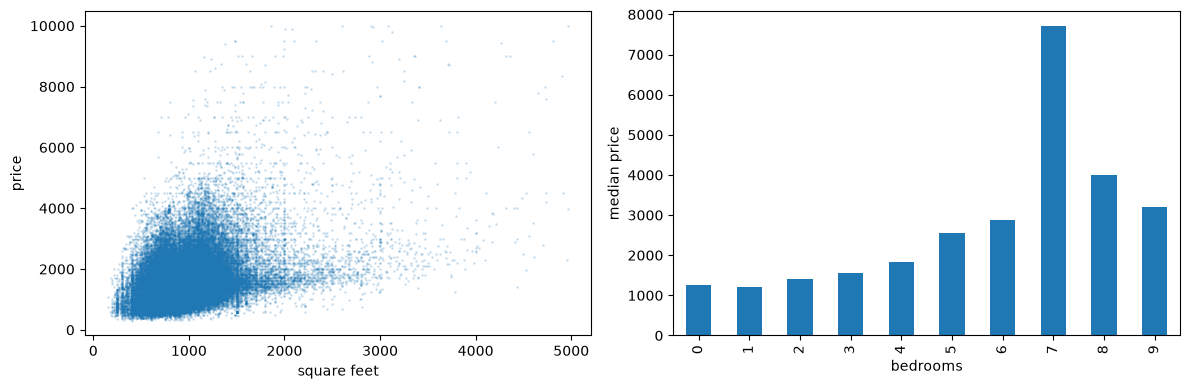

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(clean_df.square_feet, clean_df.price, s=1, alpha=.15); ax[0].set_xlabel('square feet'); ax[0].set_ylabel('price')
clean_df.groupby('bedrooms').price.median().plot.bar(ax=ax[1]); ax[1].set_ylabel('median price')
plt.tight_layout()

In [17]:
clean_df.filter(like='amenity_').mean().sort_values(ascending=False).round(3).to_frame('share of listings').T

,amenity_parking,amenity_pool,amenity_gym,amenity_patio_deck,amenity_washer_dryer,amenity_storage,amenity_clubhouse,amenity_dishwasher,amenity_ac,amenity_fireplace,amenity_refrigerator,amenity_cable_or_satellite,amenity_playground,amenity_internet_access,amenity_wood_floors,amenity_gated,amenity_tennis,amenity_tv,amenity_elevator,amenity_basketball,amenity_hot_tub,amenity_garbage_disposal,amenity_view,amenity_alarm,amenity_doorman,amenity_luxury,amenity_golf
share of listings,0.44,0.438,0.376,0.267,0.263,0.218,0.192,0.167,0.159,0.151,0.15,0.126,0.114,0.112,0.089,0.087,0.085,0.045,0.044,0.042,0.04,0.039,0.021,0.004,0.002,0.002,0.0


The cleaned file keeps all US listings.

In [20]:
from pathlib import Path
out = Path('../data/processed/apartments_clean.csv'); clean_df.to_csv(out, index=False); out, clean_df.shape

(PosixPath('../data/processed/apartments_clean.csv'), (97996, 45))